<a href="https://colab.research.google.com/github/chaithrabsrinivas/Physics-Informed-Neural-Network-for-Medicine-Clearance-Pharmacokinetics-/blob/main/python_medicine_pinn_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt



In [17]:
# 1. SET UP THE HEALTH SCENARIO
# ---------------------------------------------------------
INITIAL_DOSE = 500.0       # Patient takes 500 mg of medicine at hour 0
CLEARANCE_RATE = 0.25      # The body clears 25% of remaining medicine per hour
TOTAL_HOURS = 12.0         # We want to predict medicine levels for 12 hours


In [18]:
#2. BUILD A TINY NEURAL NETWORK
# ---------------------------------------------------------
# Input: Time in hours (1 number) -> Output: Medicine left in mg (1 number)
model = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),             # Smooth activation function ideal for physics curves
    nn.Linear(32, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)
     #Optimizer adjusts the network's internal settings to reduce mistakes
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

In [19]:
# 3. CREATE TIME CHECKPOINTS (NO REAL PATIENT DATA NEEDED)
# ---------------------------------------------------------
# 100 evenly spaced time points from hour 0 to hour 12
time_points = torch.linspace(0, TOTAL_HOURS, 100).view(-1, 1)
time_points.requires_grad = True  # Tells PyTorch to track how fast medicine drops

# Starting time point (Hour 0)
start_time = torch.tensor([[0.0]])


In [20]:
# 4. TRAIN THE AI USING HEALTH RULES
# ---------------------------------------------------------
print("Training the Medicine Clearance AI...")

for step in range(2001):
    optimizer.zero_grad()

    # RULE 1: Check the starting dose at Hour 0
    predicted_start = model(start_time)
    start_rule_error = torch.mean((predicted_start - INITIAL_DOSE) ** 2)

    # RULE 2: Check the body's clearance speed at all 100 time points
    predicted_medicine = model(time_points)

    # PyTorch automatically calculates how fast medicine is dropping right now
    drop_speed = torch.autograd.grad(
        outputs=predicted_medicine,
        inputs=time_points,
        grad_outputs=torch.ones_like(predicted_medicine),
        create_graph=True
    )[0]

    # Common-sense rule: Drop speed must equal (-CLEARANCE_RATE * current_medicine)
    physics_rule_error = torch.mean((drop_speed + CLEARANCE_RATE * predicted_medicine) ** 2)

    # Combine both rule errors and teach the AI to minimize them
    total_error = start_rule_error + physics_rule_error
    total_error.backward()
    optimizer.step()

    if step % 500 == 0:
        print(f"Step {step:4d} | Rule Error: {total_error.item():.4f}")

Training the Medicine Clearance AI...
Step    0 | Rule Error: 250366.0781
Step  500 | Rule Error: 172432.7188
Step 1000 | Rule Error: 116830.4844
Step 1500 | Rule Error: 75579.3828
Step 2000 | Rule Error: 45997.8125


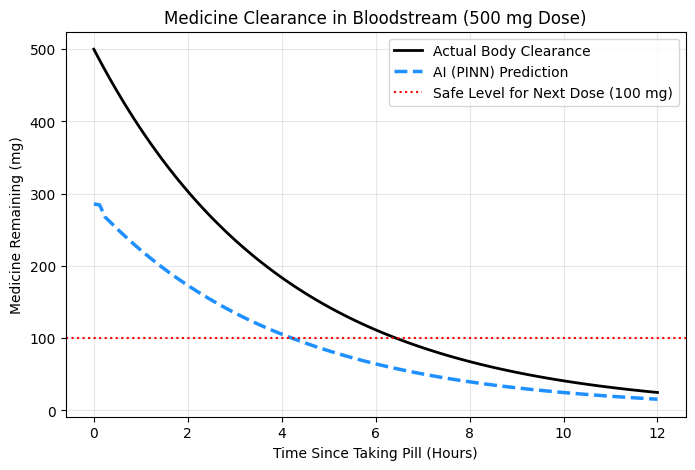

In [21]:
# 5. PLOT AND COMPARE THE RESULTS
# ---------------------------------------------------------
# Turn off gradient tracking to make final predictions
test_hours = torch.linspace(0, TOTAL_HOURS, 100).view(-1, 1)
with torch.no_grad():
    ai_predictions = model(test_hours).numpy()

# True medical formula (used only to verify our AI got it right)
true_levels = INITIAL_DOSE * torch.exp(-CLEARANCE_RATE * test_hours).numpy()

# Draw the graph
plt.figure(figsize=(8, 5))
plt.plot(test_hours.numpy(), true_levels, label="Actual Body Clearance", color="black", linewidth=2)
plt.plot(test_hours.numpy(), ai_predictions, label="AI (PINN) Prediction", color="dodgerblue", linestyle="--", linewidth=2.5)
plt.axhline(100, color="red", linestyle=":", label="Safe Level for Next Dose (100 mg)")

plt.title("Medicine Clearance in Bloodstream (500 mg Dose)")
plt.xlabel("Time Since Taking Pill (Hours)")
plt.ylabel("Medicine Remaining (mg)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()